# CordsNet-R8 on the TVSD THINGS stimuli: entropy

Frozen pretrained CordsNet-R8 (original 1000-way ImageNet readout), all 22,348 TVSD stimuli, outputs of `inference/run_inference.py`.
Entropy is of the softmax probabilities over the 1000 ImageNet classes, in nats (uniform = ln 1000 = 6.91). Set `RUN_DIR` to the downloaded run folder.

In [3]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

RUN_DIR = Path("~/Desktop/cordsnet_runs/").expanduser()
out = np.load(RUN_DIR / "outputs.npz")
names = json.load(open("imagenet_classes.json"))

entropy, entropy_t, time_ms = out["entropy"], out["entropy_t"], out["time_ms"]
pred, max_prob, concept, split = out["pred_label"], out["max_prob"], out["concept"], out["split"]
H_MAX = np.log(1000)
print(f"{len(entropy)} images | mean entropy {entropy.mean():.2f} nats (uniform {H_MAX:.2f}) | mean max prob {max_prob.mean():.2f}")

22348 images | mean entropy 2.16 nats (uniform 6.91) | mean max prob 0.49


## 1. Distribution of entropy at the last timestep

Histogram of each image's entropy at 200 ms after stimulus onset.
x: entropy (nats); y: number of images. Dashed line: uniform-distribution maximum; red line: median.

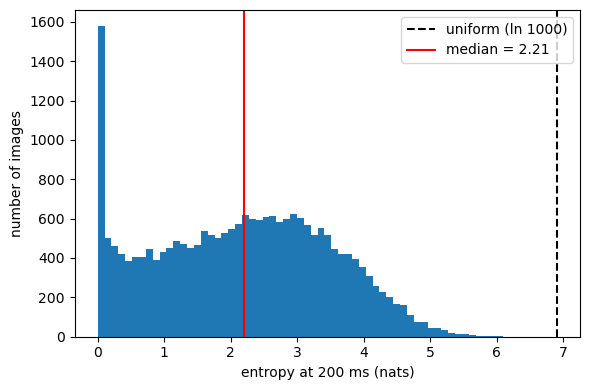

In [4]:
plt.figure(figsize=(6, 4))
plt.hist(entropy, bins=60)
plt.axvline(H_MAX, color="k", ls="--", label="uniform (ln 1000)")
plt.axvline(np.median(entropy), color="r", label=f"median = {np.median(entropy):.2f}")
plt.xlabel("entropy at 200 ms (nats)")
plt.ylabel("number of images")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Entropy over time

Mean entropy across all images at each of the 100 stimulus timesteps (2 ms each); shaded band = 25th to 75th percentile across images.
x: time after stimulus onset (ms); y: entropy (nats).

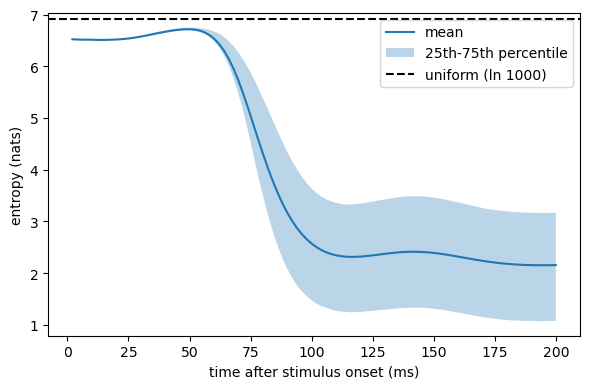

In [5]:
q25, q75 = np.percentile(entropy_t, [25, 75], axis=0)
plt.figure(figsize=(6, 4))
plt.plot(time_ms, entropy_t.mean(axis=0), label="mean")
plt.fill_between(time_ms, q25, q75, alpha=0.3, label="25th-75th percentile")
plt.axhline(H_MAX, color="k", ls="--", label="uniform (ln 1000)")
plt.xlabel("time after stimulus onset (ms)")
plt.ylabel("entropy (nats)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Concepts ranked by mean entropy

Training images only (12 per concept). Mean last-timestep entropy per THINGS concept; left: 20 lowest (most confident), right: 20 highest.
x: mean entropy (nats); y: THINGS concept.

1854 concepts | per-concept mean entropy from 0.00 to 5.26


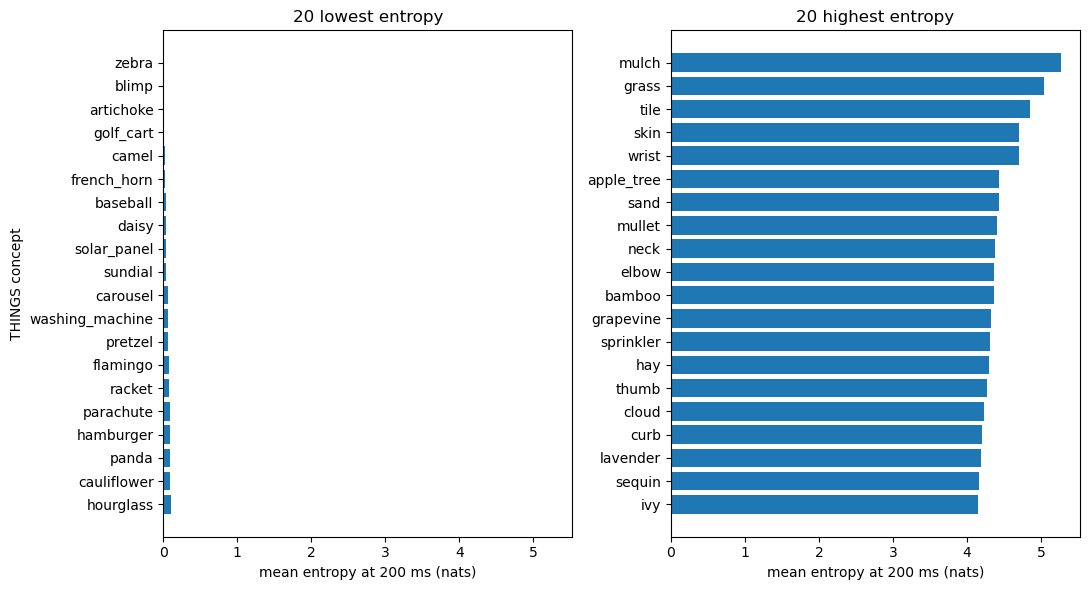

In [6]:
train = split == "train"
concepts, inv = np.unique(concept[train], return_inverse=True)
concept_entropy = np.bincount(inv, weights=entropy[train]) / np.bincount(inv)
order = np.argsort(concept_entropy)
print(f"{len(concepts)} concepts | per-concept mean entropy from {concept_entropy.min():.2f} to {concept_entropy.max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharex=True)
for ax, idx, title in [(axes[0], order[:20], "20 lowest entropy"), (axes[1], order[-20:][::-1], "20 highest entropy")]:
    ax.barh(concepts[idx][::-1], concept_entropy[idx][::-1])
    ax.set_title(title)
    ax.set_xlabel("mean entropy at 200 ms (nats)")
axes[0].set_ylabel("THINGS concept")
plt.tight_layout()
plt.show()

## 4. Most frequent predicted ImageNet classes

All 22,348 images; for each ImageNet class, the number of images whose top (argmax) prediction is that class; 20 most frequent.
x: number of images; y: ImageNet class.

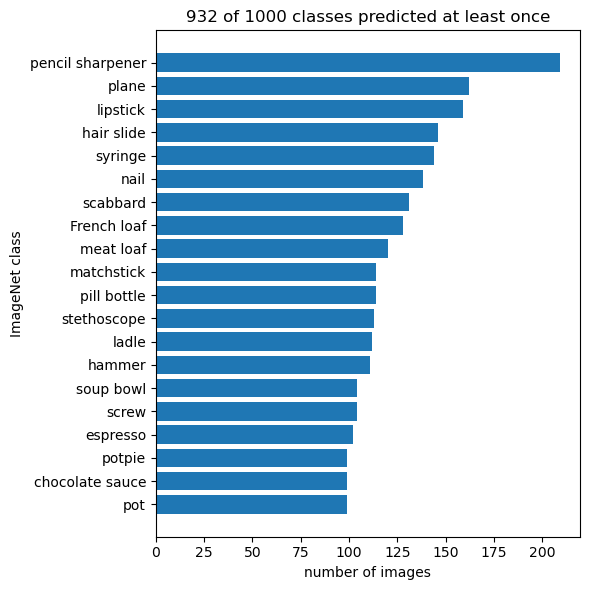

In [7]:
classes, counts = np.unique(pred, return_counts=True)
top = np.argsort(counts)[::-1][:20]
plt.figure(figsize=(6, 6))
plt.barh([names[c] for c in classes[top]][::-1], counts[top][::-1])
plt.xlabel("number of images")
plt.ylabel("ImageNet class")
plt.title(f"{len(classes)} of 1000 classes predicted at least once")
plt.tight_layout()
plt.show()